<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 18: RNN, LSTM and GRU Hyperparameter Experimentation

**Category**: CO3 – Sequence Models (RNN, LSTM, GRU)  
**Objective**: Systematically benchmark parameter complexity and convergence behavior across RNN, LSTM, and GRU cell architectures.


### Task 1: Systematic Architecture Comparison: RNN vs. LSTM vs. GRU


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# Sequence forecasting dataset
np.random.seed(42)
N, L = 200, 25
X_arr = np.sin(np.linspace(0, 20, N * L)).reshape(N, L, 1).astype(np.float32)
y_arr = np.cos(np.linspace(1, 21, N)).reshape(N, 1).astype(np.float32)

X_t = torch.tensor(X_arr)
y_t = torch.tensor(y_arr)

cell_types = ['RNN', 'LSTM', 'GRU']
hidden_dims = [16, 32]
results = []

for c_type in cell_types:
    for h_dim in hidden_dims:
        if c_type == 'RNN':
            rnn_layer = nn.RNN(1, h_dim, batch_first=True)
        elif c_type == 'LSTM':
            rnn_layer = nn.LSTM(1, h_dim, batch_first=True)
        else:
            rnn_layer = nn.GRU(1, h_dim, batch_first=True)

        fc_layer = nn.Linear(h_dim, 1)
        params = list(rnn_layer.parameters()) + list(fc_layer.parameters())
        n_params = sum(p.numel() for p in params)

        opt = optim.Adam(params, lr=0.01)
        crit = nn.MSELoss()

        for _ in range(40):
            opt.zero_grad()
            out, _ = rnn_layer(X_t)
            pred = fc_layer(out[:, -1, :])
            loss = crit(pred, y_t)
            loss.backward()
            opt.step()

        results.append({
            "cell": c_type,
            "hidden": h_dim,
            "params": n_params,
            "loss": loss.item()
        })
        print(f"Model: {c_type:4} (Hidden: {h_dim:2}) | Total Params: {n_params:5} | Final MSE: {loss.item():.5f}")


Model: RNN  (Hidden: 16) | Total Params:   321 | Final MSE: 0.16995
Model: RNN  (Hidden: 32) | Total Params:  1153 | Final MSE: 0.16994
Model: LSTM (Hidden: 16) | Total Params:  1233 | Final MSE: 0.16952
Model: LSTM (Hidden: 32) | Total Params:  4513 | Final MSE: 0.16459
Model: GRU  (Hidden: 16) | Total Params:   929 | Final MSE: 0.15872
Model: GRU  (Hidden: 32) | Total Params:  3393 | Final MSE: 0.15584


### Task 2: Comparative Performance & Model Complexity Visualization


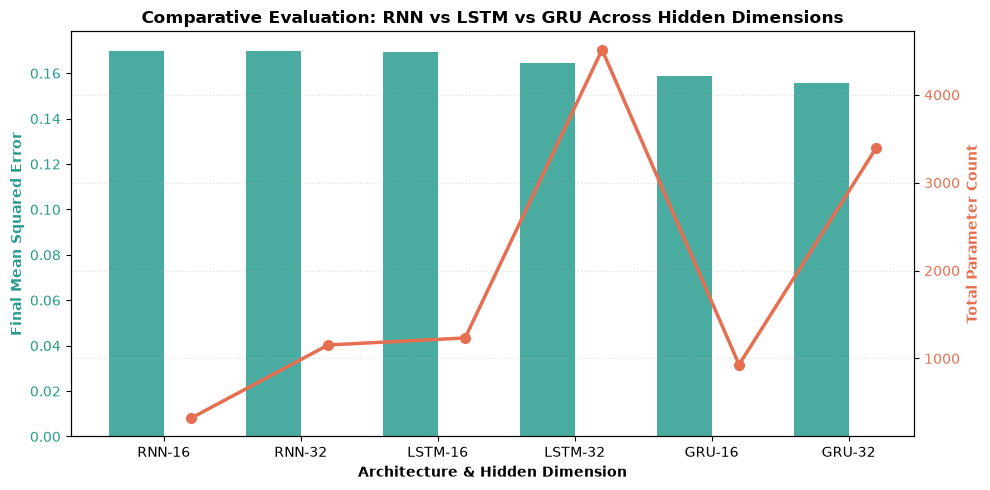

In [2]:
labels = [f"{r['cell']}-{r['hidden']}" for r in results]
losses = [r['loss'] for r in results]
params = [r['params'] for r in results]

fig, ax1 = plt.subplots(figsize=(10, 5))

color1 = '#2a9d8f'
ax1.set_xlabel('Architecture & Hidden Dimension', fontweight='bold')
ax1.set_ylabel('Final Mean Squared Error', color=color1, fontweight='bold')
bars = ax1.bar(np.arange(len(labels)) - 0.2, losses, width=0.4, color=color1, alpha=0.85, label='MSE Loss')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticks(range(len(labels)))
ax1.set_xticklabels(labels)

ax2 = ax1.twinx()
color2 = '#e76f51'
ax2.set_ylabel('Total Parameter Count', color=color2, fontweight='bold')
ax2.plot(np.arange(len(labels)) + 0.2, params, color=color2, marker='o', lw=2.5, markersize=7, label='Param Count')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title("Comparative Evaluation: RNN vs LSTM vs GRU Across Hidden Dimensions", fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.4)
fig.tight_layout()
plt.show()
